In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

In [3]:
def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

In [4]:
def getRc(dataframe):
    n_ss = sum(dataframe[dataframe.b==1]['w'])
    n_os = sum(dataframe[dataframe.b==-1]['w'])
    return (n_ss-n_os)/(n_ss+n_os)

In [5]:
def getRcs(dataframe):
    n_ss = sum(dataframe[dataframe.bs==1]['ws'])
    n_os = sum(dataframe[dataframe.bs==-1]['ws'])
    return (n_ss-n_os)/(n_ss+n_os)

In [6]:
def getRcErr(dataframe):
    n_ss = sum(dataframe[dataframe.b==1]['w'])
    n_os = sum(dataframe[dataframe.b==-1]['w'])
    n_unweighted = dataframe[dataframe.b==1].shape[0] + dataframe[dataframe.b==-1].shape[0]
    #p = n_ss/(n_ss+n_os)
    return 2*np.sqrt( n_ss * n_os / ((n_ss+n_os)**2 * n_unweighted) )

In [7]:
def getRcsErr(dataframe):
    n_ss = sum(dataframe[dataframe.bs==1]['ws'])
    n_os = sum(dataframe[dataframe.bs==-1]['ws'])
    n_unweighted = dataframe[dataframe.bs==1].shape[0] + dataframe[dataframe.bs==-1].shape[0]
    #p = n_ss/(n_ss+n_os)
    return 2*np.sqrt( n_ss * n_os / ((n_ss+n_os)**2 * n_unweighted) )

In [8]:
def calc_hist(vals, bins=10, weights=None, density=False):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    # compute histogram
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    
    # compute which bins the values are in
    digits = np.digitize(vals, bins)

    # compute the errors per bin
    # note that lowest bin value that digitize returns is 1
    # hence the range in the following list comprehension should start at 1
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    # handle normalization
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [9]:
def w_norm_per_xbin(h,x,y):
    w = np.empty([len(x)-1,len(y)-1])
    for i in range(0,len(x)-1):
        for j in range(0,len(y)-1):
            w[i][j] = h[i][j]/sum(h[i]) + 10**-50
    return w

In [10]:
observables1 = ['pt','b','dr','z','epair','w','reject','pt1','pt2','qlead','qsublead','y1','y2','phi1','phi2']
observabless1 = ['pts','bs','drs','zs','epairs','ws','rejects','pt1s','pt2s','qleads','qsubleads','y1s','y2s','phi1s','phi2s']

In [11]:
df_allreco = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all0615_chargedrc.root', "MatchedTree"),\
                      'pts>15 and bs!=-9 and reject<=0 and rejects<=0')

In [15]:
df_fakejet = applyCut(df_allreco, 'pt==-9')

In [16]:
df_fakecorr = applyCut(df_allreco, 'pt!=-9 and (b==9 or distance1>0.02 or distance2>0.02)')

In [17]:
df_allfake = applyCut(df_allreco, 'pt==-9 or b==-9 or distance1>0.02 or distance2>0.02')

In [12]:
df = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all0615_chargedrc.root', "MatchedTree"),\
              'pts>15 and bs!=-9 and b!=-9 and reject<=0 and rejects<=0')

In [13]:
distance1 = []
distance2 = []
for i in range(0,df.shape[0]):
    phi1small = min(df.iloc[i]['phi1'], df.iloc[i]['phi1s'])
    phi1large = max(df.iloc[i]['phi1'], df.iloc[i]['phi1s'])
    phi2small = min(df.iloc[i]['phi2'], df.iloc[i]['phi2s'])
    phi2large = max(df.iloc[i]['phi2'], df.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df.iloc[i]['phi1'], df.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df.iloc[i]['y1']-df.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df.iloc[i]['y2']-df.iloc[i]['y2s'])**2))
df['distance1'] = distance1
df['distance2'] = distance2

In [14]:
distance1 = []
distance2 = []
for i in range(0,df_allreco.shape[0]):
    phi1small = min(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi1large = max(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi2small = min(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    phi2large = max(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df_allreco.iloc[i]['y1']-df_allreco.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df_allreco.iloc[i]['y2']-df_allreco.iloc[i]['y2s'])**2))
df_allreco['distance1'] = distance1
df_allreco['distance2'] = distance2

Matches

In [18]:
df_match = applyCut(df, 'distance1 < 0.02 and distance2 < 0.02')

In [19]:
df_match.shape[0]

46086

Fake subtraction

In [21]:
ob = 'b'
range_low = -1.2
range_high = 1.2
bins = 2

In [20]:
df_match_20 = applyCut(df_match, '20 < pts < 25')
df_allreco_20 = applyCut(df_allreco, '20 < pts < 25')
df_fake_20 = applyCut(df_allfake, '20 < pts < 25')
df_fakejet_20 = applyCut(df_fakejet, '20 < pts < 25')
df_fakecorr_20 = applyCut(df_fakecorr, '20 < pts < 25')

Check if statistic uncertainty assigned by calc_hist is correct

In [22]:
df_fake_20_os = applyCut(df_fake_20, 'bs==-1')
df_fake_20_ss = applyCut(df_fake_20, 'bs==1')

Method 1: Don't normalize weights

In [25]:
w_array = np.unique(df_fake_20['w'])
print(w_array)

[2.15385002e-11 1.27623315e-10 5.68292191e-10 3.41630102e-09
 1.43789896e-08]


In [24]:
count_array = []
for i in range(0, len(w_array)):
    count_array.append((df_fake_20_os[df_fake_20_os.w==w_array[i]]).shape[0])
print(count_array)

[923, 2133, 643, 52, 5]


In [34]:
e = sum(df_fake_20_os['w'])
print(e)

9.070550455528292e-07


In [37]:
var = 0
for i in range(0, len(w_array)):
    var += (w_array[i])**2 * count_array[i]
std = np.sqrt(var)
print(std)

4.3399368095867767e-08


In [35]:
norm = sum(df_fake_20['w'])
print(norm)

1.4902879056505336e-06


In [38]:
print(e/norm, std/norm)

0.6086441701054306 0.029121465678756397


Method 2: Normalize weights

In [48]:
df_fake_20.eval('relw = w/9.070550455528292e-07', inplace=True)
df_fake_20_os = applyCut(df_fake_20, 'bs==-1')
df_fake_20_ss = applyCut(df_fake_20, 'bs==1')

In [49]:
w_array = np.unique(df_fake_20['relw'])
print(w_array)

[2.37455271e-05 1.40700738e-04 6.26524480e-04 3.76636571e-03
 1.58523891e-02]


In [50]:
count_array = []
for i in range(0, len(w_array)):
    count_array.append((df_fake_20_os[df_fake_20_os.relw==w_array[i]]).shape[0])
print(count_array)

[923, 2133, 643, 52, 5]


In [55]:
e = sum(df_fake_20_os['relw'])
print(e)

0.9999999999999422


In [51]:
var = 0
for i in range(0, len(w_array)):
    var += (w_array[i])**2 * count_array[i]
std = np.sqrt(var)
print(std)

0.04784645464313232


In [53]:
norm = sum(df_fake_20['relw'])
print(norm)

1.6429961036620329


In [56]:
print(e/norm, std/norm)

0.6086441701054964 0.029121465678761234


Now check the results with calc_hist

In [164]:
x

array([-1.2,  0. ,  1.2])

In [65]:
y_match_rec,yerr_match_rec,x = calc_hist(df_match_20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_20['w'], density=True)
y_allreco_rec,yerr_allreco_rec,x = calc_hist(df_allreco_20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_allreco_20['w'], density=True)
y_fake_rec,yerr_fake_rec,x = calc_hist(df_fake_20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fake_20['w'], density=True)
y_fakejet_rec,yerr_fakejet_rec,x = calc_hist(df_fakejet_20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fakejet_20['w'], density=True)
y_fakecorr_rec,yerr_fakecorr_rec,x = calc_hist(df_fakecorr_20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fakecorr_20['w'], density=True)

In [66]:
print(y_fake_rec/sum(y_fake_rec), yerr_fake_rec/sum(y_fake_rec))

[0.60864417 0.39135583] [0.02912147 0.02331168]


End checking

(0.0, 0.9950139788690435)

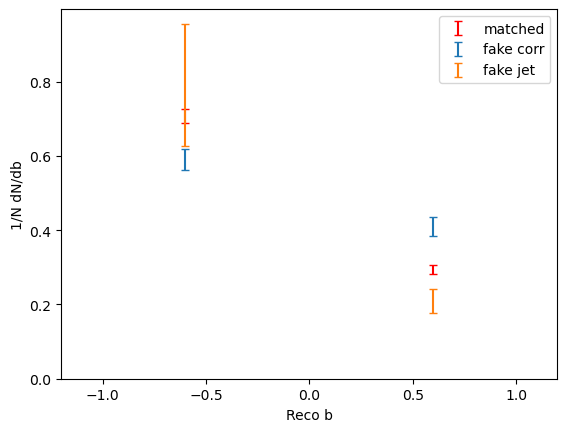

In [62]:
x=np.arange(range_low+(range_high-range_low)/(2*bins),range_high+(range_high-range_low)/(2*bins), (range_high-range_low)/bins)
#plt.errorbar(x, y_allreco_rec/sum(y_allreco_rec), yerr=yerr_allreco_rec/sum(y_allreco_rec), capsize=3, color='k', label='all reco', ls='none')
plt.errorbar(x, y_match_rec/sum(y_match_rec), yerr=yerr_match_rec/sum(y_match_rec), capsize=3, color='r', label='matched', ls='none')
#plt.errorbar(x, y_fake_rec/sum(y_fake_rec), yerr=yerr_fake_rec/sum(y_fake_rec), capsize=3, color='b', label='all fake', ls='none')
plt.errorbar(x, y_fakecorr_rec/sum(y_fakecorr_rec), yerr=yerr_fakecorr_rec/sum(y_fakecorr_rec), capsize=3, label='fake corr', ls='none')
plt.errorbar(x, y_fakejet_rec/sum(y_fakejet_rec), yerr=yerr_fakejet_rec/sum(y_fakejet_rec), capsize=3, label='fake jet', ls='none')
plt.legend()
plt.xlabel('Reco '+ob)
plt.ylabel('1/N dN/d'+ob)
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)

Why is the b==-1 errorbar so much larger than b==1?

In [80]:
norm = sum(df_fakejet_20['w'])
print(norm)

1.3852477110526396e-07


In [90]:
df_fakejet_20.eval('relw = w/1.3852477110526396e-07', inplace=True)
df_fakejet_20_os = applyCut(df_fakejet_20, 'bs==-1')
df_fakejet_20_ss = applyCut(df_fakejet_20, 'bs==1')

In [91]:
w_array = np.unique(df_fakejet_20['relw'])
print(w_array)

[0.00015548 0.0009213  0.00410246 0.02466202 0.10380085]


In [92]:
count_array_os = []
for i in range(0, len(w_array)):
    count_array_os.append((df_fakejet_20_os[df_fakejet_20_os.relw==w_array[i]]).shape[0])
print(count_array_os)

[36, 133, 69, 7, 2]


In [93]:
count_array_ss = []
for i in range(0, len(w_array)):
    count_array_ss.append((df_fakejet_20_ss[df_fakejet_20_ss.relw==w_array[i]]).shape[0])
print(count_array_ss)

[13, 95, 23, 1, 0]


In [94]:
e_os = sum(df_fakejet_20_os['relw'])
print(e_os)

0.7914363143707941


In [95]:
e_ss = sum(df_fakejet_20_ss['relw'])
print(e_ss)

0.20856368562920657


In [96]:
var_os = 0
for i in range(0, len(w_array)):
    var_os += (w_array[i])**2 * count_array_os[i]
std_os = np.sqrt(var_os)
print(std_os)

0.1645654412885551


In [97]:
var_ss = 0
for i in range(0, len(w_array)):
    var_ss += (w_array[i])**2 * count_array_ss[i]
std_ss = np.sqrt(var_ss)
print(std_ss)

0.03280639416373494


In [99]:
norm = sum(df_fakejet_20['relw'])
print(norm)

1.0000000000000002


In [100]:
print(e_os/norm, std_os/norm)

0.7914363143707939 0.16456544128855508


In [101]:
print(e_ss/norm, std_ss/norm)

0.20856368562920652 0.03280639416373493


In [83]:
# consistent with:
print(y_fakejet_rec/sum(y_fakejet_rec))
print(yerr_fakejet_rec/sum(y_fakejet_rec))

[0.79143631 0.20856369]
[0.16456544 0.03280639]


In [63]:
(y_allreco_rec/sum(y_allreco_rec))/(y_match_rec/sum(y_match_rec))
print(y_fake_rec/sum(y_fake_rec))
print(y_fakejet_rec/sum(y_fakejet_rec))
print(y_fakecorr_rec/sum(y_fakecorr_rec))

[0.60864417 0.39135583]
[0.79143631 0.20856369]
[0.58991216 0.41008784]
